In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_23025/687462750.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'
ANALYSIS_PATH = '../../analysis'
INTERMEDIARY_RESULTS = f"{ANALYSIS_PATH}/intermediary_data"

MERGEGEN_DATASET2 = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_TypeScript_model_dataset2_TypeScript_similarities.csv"
SBCR_DATASET2 = f"{SBCR_RESULTS}/rq2_TypeScript/RESULTS/results_evaluate_dataset2_TypeScript_combination_rq2_TypeScript_seed-3022024.xlsx"

DATASET2_COMPLETE = f"{DATA_PATH}/dataset2_TypeScript_complete.json" 
DATASET2_TESTING = f"{DATA_PATH}/dataset2_TypeScript_testing.json"
DATASET2_METADATA = f"{DATA_PATH}/dataset2_TypeScript_metadata.json"
DATASET2_STATS = f"{DATA_PATH}/dataset2_TypeScript_complete_stats.csv"

MERGEGEN_BETTER = f"{INTERMEDIARY_RESULTS}/rq4_dataset2_TypeScript_qualitative_list_MergegenBetter.csv"
SBCR_BETTER = f"{INTERMEDIARY_RESULTS}/rq4_dataset2_TypeScript_qualitative_list_SBCRBetter.csv"

In [3]:
df_complete_ds2 = pd.read_json(DATASET2_COMPLETE)

In [4]:
df_test_ds2 = pd.read_json(DATASET2_TESTING)
df_test_ds2

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,merge_id,chunk_number
0,"v27 = {\n ""kind"": ""LinkedField"",\n ""alias"": ...","v27 = {\n ""kind"": ""LinkedField"",\n ""alias"": ...",\nv18 = [\n,v19 = [\n,34487,7
1,"""scroll-padding-bottom""?: ScrollPaddingBotto...","""scroll-padding-bottom""?: Property.ScrollPad...","\n ""scroll-padding-bottom""?: ScrollPaddingBot...","""scroll-padding-bottom""?: Property.ScrollPad...",50552,32
2,"state: [''],\n countryCode: ...","state: [''],\n country: ...","\n state: ['', Validators.required...","state: [''],\n country: ...",32503,2
3,});\n,,"\n\n describe('GroupBy ', () => {\n ...","\n describe('GroupBy ', () => {\n be...",42572,3
4,"function createSortName(client: Client, sortNa...",,\nfunction createSortName(client: Client): str...,,39671,1
...,...,...,...,...,...,...
1346,this.dialogRef.afterOpen().subscribe(x => {\n,this.subscription.push(this.dialogRef.afte...,\n this.dialogRef.afterOpen().subscribe(x =...,this.subscription.push(this.dialogRef.afte...,40517,3
1347,if (row.highestBlockNumber === null)...,const fromBlock: number = (!row || !...,\n if (row.highestBlockNumber === nul...,if (row.highestBlockNumber === null)...,39322,2
1348,,"import {Broadcaster} from ""../subscriber/Broad...","\nimport {SqlInMemory} from ""../driver/SqlInMe...","import {SqlInMemory} from ""../driver/SqlInMemo...",5468,1
1349,"<location filename=""../GUI/PageInput.c...","<location filename=""../GUI/PageInput.c...","\n <location filename=""../GUI/PageInput...","<location filename=""../GUI/PageInput.c...",45660,37


In [5]:
df_mergegen_ds2 = pd.read_csv(MERGEGEN_DATASET2)
data = []
for index, row in df_mergegen_ds2.iterrows():
    chunk = df_complete_ds2.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen_ds2['chunk_id'] = data
df_mergegen_ds2 = df_mergegen_ds2.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds2

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
0,11446,0.000000,0.000000,0.273332,1.000000,0.000000,0.500000,FAIL,16402-3
1,9920,0.991087,0.990403,0.512992,0.605898,0.990366,0.798132,FAIL,53413-1
2,873,0.446927,0.446429,1.155791,1.000000,0.571429,0.785714,FAIL,25010-1
3,166,0.589474,0.589595,0.343001,1.000000,0.589595,0.794798,FAIL,23454-2
4,6459,0.726378,0.456976,1.287388,0.390115,0.474477,0.432296,FAIL,50739-1
...,...,...,...,...,...,...,...,...,...
1346,12393,1.000000,1.000000,0.222497,1.000000,0.884120,0.942060,SUCCEED,15650-68
1347,7167,1.000000,1.000000,1.217788,0.000000,1.000000,0.500000,SUCCEED,40814-3
1348,5928,1.000000,0.888889,0.044588,0.526316,0.246154,0.386235,SUCCEED,19673-14
1349,2351,1.000000,1.000000,0.424611,1.000000,0.000000,0.500000,SUCCEED,54642-11


In [6]:
df_mergegen_ds2.describe()

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim
count,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000
mean,6788.686899,0.868889,0.868185,0.422088,0.735660,0.688452,0.712056
std,3890.570577,0.243618,0.250645,0.380981,0.283424,0.311139,0.195921
min,3.000000,0.000000,0.000000,0.037825,0.000000,0.000000,0.000000
25%,3476.500000,0.809401,0.842330,0.164951,0.606871,0.528196,0.587064
50%,6809.000000,1.000000,1.000000,0.260314,0.826772,0.802198,0.722611
75%,10157.000000,1.000000,1.000000,0.505198,0.967086,0.942733,0.868835
max,13486.000000,1.000000,1.000000,1.314682,1.000000,1.000000,1.000000


In [7]:
df_sbcr_ds2 = pd.read_excel(SBCR_DATASET2)
df_sbcr_ds2 = df_sbcr_ds2.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_ds2.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
187,10207-2,0.773924,0.816054,ok,9.065849
449,10559-1,0.961080,1.000000,ok,12.793229
437,10579-3,0.765750,0.853119,ok,5.280971
191,10611-1,0.700686,0.783133,ok,12.148646
359,10694-3,0.924041,0.952381,ok,1.623045
...,...,...,...,...,...
180,9889-1,0.652337,1.000000,ok,12.187519
122,9891-2,0.853393,0.947368,ok,7.946712
181,9950-3,0.804029,0.887967,ok,7.544048
50,9981-1,0.721709,0.710801,ok,12.815568


In [8]:
df_results_ds2 = df_sbcr_ds2[['chunk_id', 'fitness_sbcr', 'sim_sbcr', 'time_sbcr']].merge(df_mergegen_ds2[['chunk_index', 'chunk_id', 'sim_mergegen', 'time_mergegen', 'mergegen_parents_sim']], on='chunk_id', suffixes=('_sbcr', '_mergegen'))
df_results_ds2

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim
0,19483-3,0.669062,0.876190,1.313238,9992,0.977848,0.439757,0.615394
1,21390-1,0.511808,0.787879,13.931805,1143,0.740741,0.070146,0.277778
2,53821-1,0.827774,0.766169,11.873679,4079,0.607692,0.253651,0.629298
3,24192-2,0.876761,0.468874,4.081827,10956,0.460690,1.286229,0.858885
4,51310-11,0.833117,0.871345,2.046585,5226,1.000000,0.196624,0.841957
...,...,...,...,...,...,...,...,...
502,51214-11,0.833117,0.871345,5.825620,8289,1.000000,0.195628,0.841957
503,30731-1,0.962690,1.000000,14.060799,12931,1.000000,0.235178,0.958530
504,30055-2,0.503282,0.432056,17.143595,9118,1.000000,0.132322,0.220930
505,51351-7,0.833117,0.871345,7.474702,9736,1.000000,0.196367,0.841957


In [9]:
print(df_results_ds2['sim_sbcr'].isnull().sum()) 
df_results_clean = df_results_ds2.dropna(subset=['sim_sbcr', 'sim_mergegen'])

0


In [10]:
print(df_results_clean[['sim_sbcr', 'sim_mergegen', 'time_sbcr', 'time_mergegen']].describe())

         sim_sbcr  sim_mergegen   time_sbcr  time_mergegen
count  507.000000    507.000000  507.000000     507.000000
mean     0.787889      0.873523    8.675076       0.440659
std      0.221928      0.246063    9.996474       0.378084
min      0.025304      0.000000    0.304102       0.037825
25%      0.687018      0.857602    2.729149       0.196617
50%      0.871345      1.000000   10.017260       0.273890
75%      0.959968      1.000000   12.583856       0.524649
max      1.000000      1.000000  154.860638       1.314682


In [11]:
df_results_clean['diff'] = df_results_clean['sim_sbcr'] - df_results_clean['sim_mergegen']
df_results_clean

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff
0,19483-3,0.669062,0.876190,1.313238,9992,0.977848,0.439757,0.615394,-0.101658
1,21390-1,0.511808,0.787879,13.931805,1143,0.740741,0.070146,0.277778,0.047138
2,53821-1,0.827774,0.766169,11.873679,4079,0.607692,0.253651,0.629298,0.158477
3,24192-2,0.876761,0.468874,4.081827,10956,0.460690,1.286229,0.858885,0.008185
4,51310-11,0.833117,0.871345,2.046585,5226,1.000000,0.196624,0.841957,-0.128655
...,...,...,...,...,...,...,...,...,...
502,51214-11,0.833117,0.871345,5.825620,8289,1.000000,0.195628,0.841957,-0.128655
503,30731-1,0.962690,1.000000,14.060799,12931,1.000000,0.235178,0.958530,0.000000
504,30055-2,0.503282,0.432056,17.143595,9118,1.000000,0.132322,0.220930,-0.567944
505,51351-7,0.833117,0.871345,7.474702,9736,1.000000,0.196367,0.841957,-0.128655


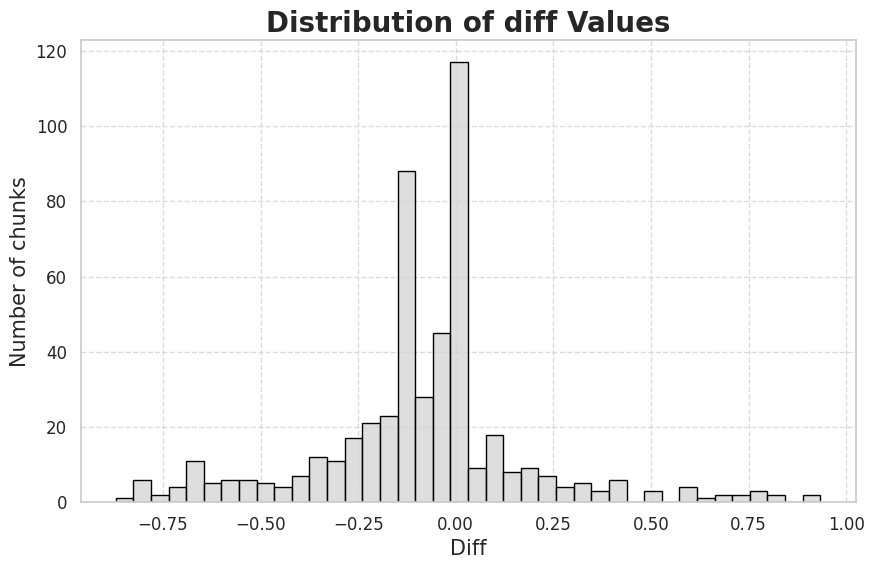

In [12]:
# close to 1 = sbcr is better
# close to -1 = mergegen is better
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(10, 6))
ax = sns.histplot(df_results_clean['diff'],color='lightgray', edgecolor='black')

plt.title('Distribution of diff Values', fontsize=20, weight='bold')
plt.xlabel('Diff', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)

# plt.savefig('RQ4_histogram_z_distribution.png', dpi=300, bbox_inches='tight')

plt.show()

In [13]:
df_stats = pd.read_csv(DATASET2_STATS)
df = df_results_clean.merge(df_stats, on='chunk_id')
df['diff_chunk_solution'] = df['chunk_size_char'] - df['solution_size_char']
df['chunk_diff_lines'] = df['v1_size'] - df['v2_size']
df['v1_size_rel'] = df['v1_size']/(df['v1_size'] + df['v2_size'])
df['v2_size_rel'] = df['v2_size']/(df['v1_size'] + df['v2_size'])
df['chunk_diff_lines_rel'] = df['v1_size_rel'] - df['v2_size_rel']
df['chunk_diff_char'] = df['v1_size_char'] - df['v2_size_char']
df['v1_size_char_rel'] = df['v1_size_char']/(df['v1_size_char'] + df['v2_size_char'])
df['v2_size_char_rel'] = df['v2_size_char']/(df['v1_size_char'] + df['v2_size_char'])
df['chunk_diff_char_rel'] = df['v1_size_char_rel'] - df['v2_size_char_rel']
df

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
0,19483-3,0.669062,0.876190,1.313238,9992,0.977848,0.439757,0.615394,-0.101658,13,...,0.621901,4,5,0.692308,0.307692,0.384615,198,0.776536,0.223464,0.553073
1,21390-1,0.511808,0.787879,13.931805,1143,0.740741,0.070146,0.277778,0.047138,4,...,0.420430,22,2,0.750000,0.250000,0.500000,60,0.983871,0.016129,0.967742
2,53821-1,0.827774,0.766169,11.873679,4079,0.607692,0.253651,0.629298,0.158477,5,...,0.763250,33,-1,0.400000,0.600000,-0.200000,-14,0.455696,0.544304,-0.088608
3,24192-2,0.876761,0.468874,4.081827,10956,0.460690,1.286229,0.858885,0.008185,15,...,0.525232,827,-3,0.400000,0.600000,-0.200000,137,0.568159,0.431841,0.136318
4,51310-11,0.833117,0.871345,2.046585,5226,1.000000,0.196624,0.841957,-0.128655,8,...,0.828431,145,2,0.625000,0.375000,0.250000,85,0.644068,0.355932,0.288136
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
502,51214-11,0.833117,0.871345,5.825620,8289,1.000000,0.195628,0.841957,-0.128655,8,...,0.828431,145,2,0.625000,0.375000,0.250000,85,0.644068,0.355932,0.288136
503,30731-1,0.962690,1.000000,14.060799,12931,1.000000,0.235178,0.958530,0.000000,5,...,0.962639,134,-1,0.400000,0.600000,-0.200000,-13,0.476534,0.523466,-0.046931
504,30055-2,0.503282,0.432056,17.143595,9118,1.000000,0.132322,0.220930,-0.567944,5,...,0.236074,163,3,0.800000,0.200000,0.600000,225,0.995595,0.004405,0.991189
505,51351-7,0.833117,0.871345,7.474702,9736,1.000000,0.196367,0.841957,-0.128655,8,...,0.828431,145,2,0.625000,0.375000,0.250000,85,0.644068,0.355932,0.288136


In [14]:
# cases where mergeGen is better
print(len(df[df['diff'] < 0]))
df.sort_values('diff').to_csv(MERGEGEN_BETTER)
df.sort_values('diff').head(20)


327


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
472,21360-4,0.544909,0.128924,11.899672,9230,1.000000,0.266250,0.545077,-0.871076,54,...,0.536578,2115,-50,0.037037,0.962963,-0.925926,-1994,0.060793,0.939207,-0.878414
343,6859-1,0.514472,0.042644,7.287438,8891,0.861671,1.284170,0.463413,-0.819028,57,...,0.519750,43,-55,0.017544,0.982456,-0.964912,-1365,0.021724,0.978276,-0.956552
498,5927-1,0.593350,0.188352,1.951525,2693,1.000000,0.945080,0.600290,-0.811648,17,...,0.589473,74,13,0.882353,0.117647,0.764706,651,0.903346,0.096654,0.806691
56,50551-3,0.631771,0.200935,1.474711,9490,1.000000,0.088840,0.496942,-0.799065,11,...,0.484846,416,7,0.818182,0.181818,0.636364,324,0.852174,0.147826,0.704348
322,38144-2,0.605316,0.202561,5.485503,12122,1.000000,0.585608,0.586136,-0.797439,19,...,0.588604,49,-15,0.105263,0.894737,-0.789474,-646,0.107056,0.892944,-0.785888
217,15415-1,0.562453,0.209424,1.165978,5871,1.000000,0.088428,0.435757,-0.790576,14,...,0.441302,317,-12,0.071429,0.928571,-0.857143,-317,0.065753,0.934247,-0.868493
78,18427-5,0.595051,0.204598,1.960279,3351,0.989399,1.286325,0.608616,-0.784802,27,...,0.592510,82,-21,0.111111,0.888889,-0.777778,-688,0.103687,0.896313,-0.792627
423,21260-1,0.546782,0.104410,5.927124,13220,0.860778,1.283160,0.482240,-0.756368,31,...,0.551971,56,-27,0.064516,0.935484,-0.870968,-999,0.052820,0.947180,-0.894360
388,35683-2,0.617194,0.246684,3.469115,3901,1.000000,0.156144,0.613998,-0.753316,21,...,0.594117,662,17,0.904762,0.095238,0.809524,574,0.879630,0.120370,0.759259
263,5515-3,0.500696,0.285369,2.956946,2566,1.000000,0.151950,0.147260,-0.714631,33,...,0.151805,597,31,0.969697,0.030303,0.939394,715,0.998605,0.001395,0.997211


In [15]:
# cases where sbcr is better
print(len(df[df['diff'] > 0]))
df.sort_values('diff', ascending=False).to_csv(SBCR_BETTER)
df.sort_values('diff', ascending=False).head(20)

104


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
59,5056-16,0.501372,0.933860,1.423917,5953,0.000000,0.732056,0.500000,0.933860,20,...,0.469281,68,18,0.950000,0.050000,0.900000,543,0.998165,0.001835,0.996330
261,5622-1,0.498969,0.925170,0.770673,6676,0.000000,0.331556,0.500000,0.925170,15,...,0.462389,34,-15,0.000000,1.000000,-1.000000,-243,0.000000,1.000000,-1.000000
321,16402-3,0.498480,0.841727,15.029548,11446,0.000000,0.273332,0.500000,0.841727,6,...,0.419014,46,-6,0.000000,1.000000,-1.000000,-165,0.000000,1.000000,-1.000000
363,56019-6,0.671833,0.800000,13.083648,5391,0.000000,0.149659,0.500000,0.800000,5,...,0.638601,47,-1,0.400000,0.600000,-0.200000,-68,0.173077,0.826923,-0.653846
310,43478-2,0.497229,0.792636,2.867691,9858,0.000000,0.528003,0.500000,0.792636,26,...,0.393130,222,-26,0.000000,1.000000,-1.000000,-635,0.000000,1.000000,-1.000000
469,35742-19,0.957150,0.930628,15.038406,6842,0.149721,1.285002,0.161360,0.780907,36,...,0.947918,1497,-12,0.333333,0.666667,-0.333333,-96,0.485723,0.514277,-0.028554
325,24017-2,0.499677,0.762058,3.659189,3847,0.000000,0.800105,0.500000,0.762058,29,...,0.384366,296,27,0.965517,0.034483,0.931034,773,0.998710,0.001290,0.997419
426,24936-1,0.498845,0.716418,11.534429,3729,0.000000,0.262243,0.500000,0.716418,3,...,0.357988,96,-3,0.000000,1.000000,-1.000000,-217,0.000000,1.000000,-1.000000
116,48668-1,0.494563,0.905812,15.309420,5841,0.190436,0.862073,0.125092,0.715377,64,...,0.456335,423,62,0.984375,0.015625,0.968750,2601,0.999616,0.000384,0.999232
176,17765-1,0.615657,0.894985,12.897531,10289,0.203267,1.289798,0.237763,0.691718,58,...,0.601840,15,36,0.810345,0.189655,0.620690,1472,0.827986,0.172014,0.655971


In [16]:
df_mergegen = df[df['diff'] < 0]
df_sbcr = df[df['diff'] > 0]

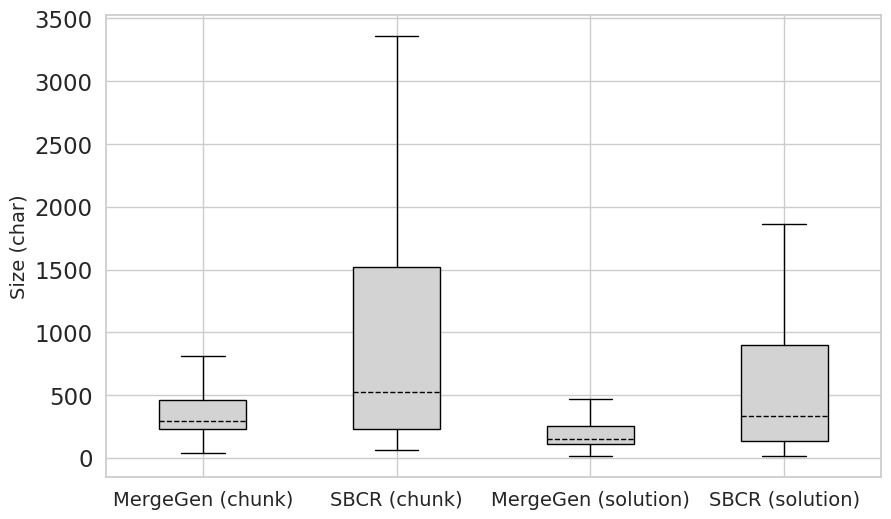

In [17]:
# Create a boxplot
plt.figure(figsize=(10, 6))  # Set the figure size
plt.boxplot([df_mergegen['chunk_size_char'], df_sbcr['chunk_size_char'], df_mergegen['solution_size_char'], df_sbcr['solution_size_char']], 
            patch_artist=True,  # To fill the box with color
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  # Color of the median line
            boxprops=dict(facecolor='lightgray', color='black'),  # Color of the box
            whiskerprops=dict(color='black'),  # Color of the whiskers
            capprops=dict(color='black'),  # Color of the caps
            showfliers=False)  # Properties of the outliers

# Customize labels and title
# plt.xlabel('Your X Label')
plt.ylabel('Size (char)', fontsize=14)
plt.xticks([1, 2, 3, 4], ['MergeGen (chunk)', 'SBCR (chunk)', 'MergeGen (solution)', 'SBCR (solution)'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)

# Save or show the plot
# plt.savefig('RQ3_boxplots.png', dpi=300)  # Save the plot as a PNG file with higher resolution
plt.show()  # Show the plot

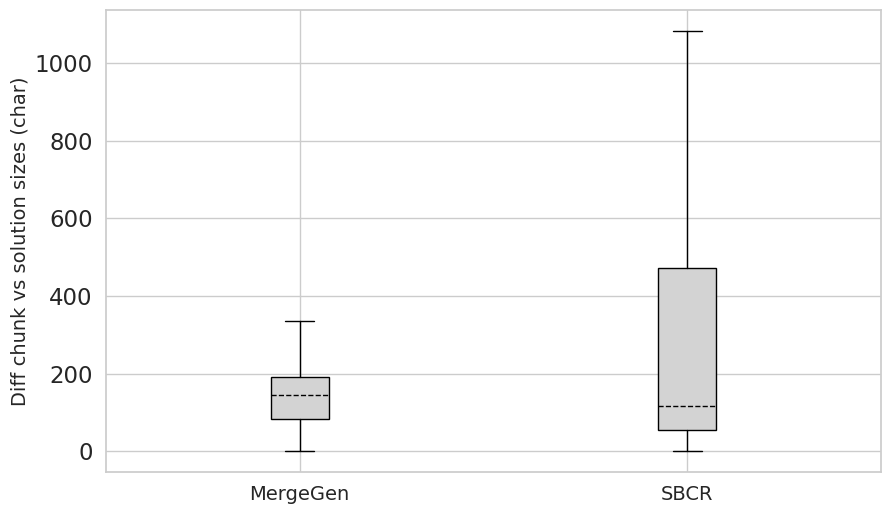

In [18]:
plt.figure(figsize=(10, 6))  # Set the figure size
plt.boxplot([df_mergegen['diff_chunk_solution'], df_sbcr['diff_chunk_solution']], 
            patch_artist=True,  # To fill the box with color
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  # Color of the median line
            boxprops=dict(facecolor='lightgray', color='black'),  # Color of the box
            whiskerprops=dict(color='black'),  # Color of the whiskers
            capprops=dict(color='black'),  # Color of the caps
            showfliers=False)  # Properties of the outliers

plt.ylabel('Diff chunk vs solution sizes (char)', fontsize=14)
plt.xticks([1, 2], ['MergeGen', 'SBCR'], fontsize=14)

plt.show()  # Show the plot

In [19]:
print(df_mergegen[['fitness_sbcr','diff_chunk_solution']].describe())
print(df_sbcr[['fitness_sbcr','diff_chunk_solution']].describe())
            

       fitness_sbcr  diff_chunk_solution
count    327.000000           327.000000
mean       0.775204           241.192661
std        0.136903           445.590340
min        0.403248             1.000000
25%        0.695676            83.500000
50%        0.829961           145.000000
75%        0.865224           190.500000
max        0.992103          5069.000000
       fitness_sbcr  diff_chunk_solution
count    104.000000           104.000000
mean       0.702052           449.115385
std        0.168078           896.143477
min        0.347888             1.000000
25%        0.512908            55.500000
50%        0.716829           116.500000
75%        0.840889           470.750000
max        0.992687          5556.000000


In [20]:
df['fitness_to_solution_diff'] = df['mergegen_parents_sim'] - df['fitness_sbcr']

In [21]:
df[(df['diff'] < 0) & (df['mergegen_parents_sim'] > df['fitness_sbcr'])].sort_values('fitness_to_solution_diff', ascending=False)

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel,fitness_to_solution_diff
312,37502-2,0.688088,0.868502,11.082744,6145,1.000000,0.801326,0.767993,-0.131498,61,...,1218,-43,0.147541,0.852459,-0.704918,-809,0.260225,0.739775,-0.479549,0.079905
131,30734-2,0.785945,0.656814,2.910048,10947,1.000000,0.221397,0.848874,-0.343186,10,...,364,-6,0.200000,0.800000,-0.600000,-145,0.371681,0.628319,-0.256637,0.062929
345,41856-19,0.782051,0.891386,1.515104,434,1.000000,0.337059,0.836066,-0.108614,13,...,117,-9,0.153846,0.846154,-0.692308,-161,0.288714,0.711286,-0.422572,0.054014
42,7516-2,0.618654,0.944625,3.616839,7433,1.000000,0.259115,0.663016,-0.055375,15,...,70,11,0.866667,0.133333,0.733333,267,0.867769,0.132231,0.735537,0.044361
392,29798-1,0.831241,0.968815,0.555251,9555,1.000000,0.298321,0.875034,-0.031185,14,...,128,-6,0.285714,0.714286,-0.428571,-123,0.336870,0.663130,-0.326260,0.043793
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
301,30538-2,0.992103,0.990415,12.006021,11032,1.000000,0.209450,0.992366,-0.009585,5,...,159,-1,0.400000,0.600000,-0.200000,3,0.504762,0.495238,0.009524,0.000263
472,21360-4,0.544909,0.128924,11.899672,9230,1.000000,0.266250,0.545077,-0.871076,54,...,2115,-50,0.037037,0.962963,-0.925926,-1994,0.060793,0.939207,-0.878414,0.000168
391,44218-1,0.784553,0.507614,13.460567,5516,0.508108,0.356570,0.784679,-0.000494,4,...,64,0,0.500000,0.500000,0.000000,58,0.610687,0.389313,0.221374,0.000126
65,12458-1,0.603330,0.439141,7.631854,2906,0.595420,0.196675,0.603448,-0.156279,8,...,262,4,0.750000,0.250000,0.500000,276,0.879121,0.120879,0.758242,0.000119


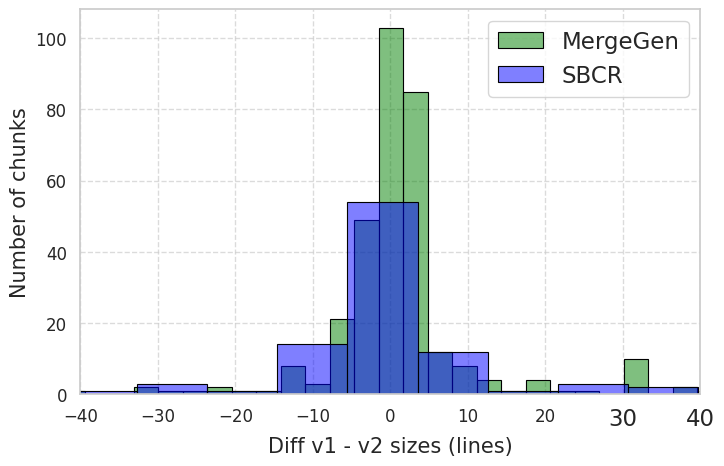

In [22]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_lines'], bins=50, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_lines'],bins=50, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (lines)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-40,40)
plt.legend()
plt.show()

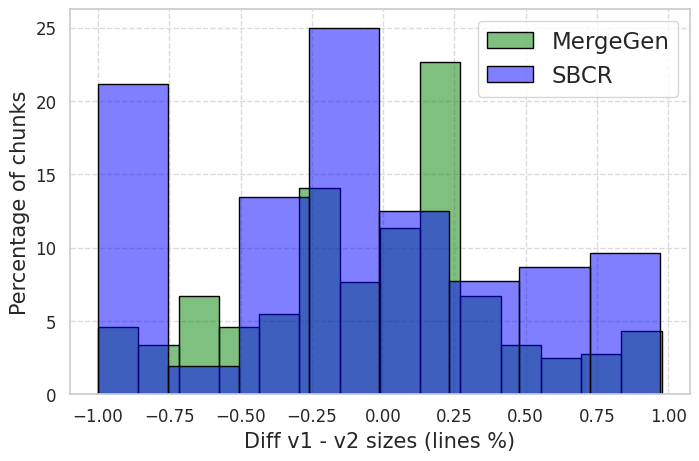

In [23]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_lines_rel'], stat='percent',color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_lines_rel'], stat='percent', color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (lines %)', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

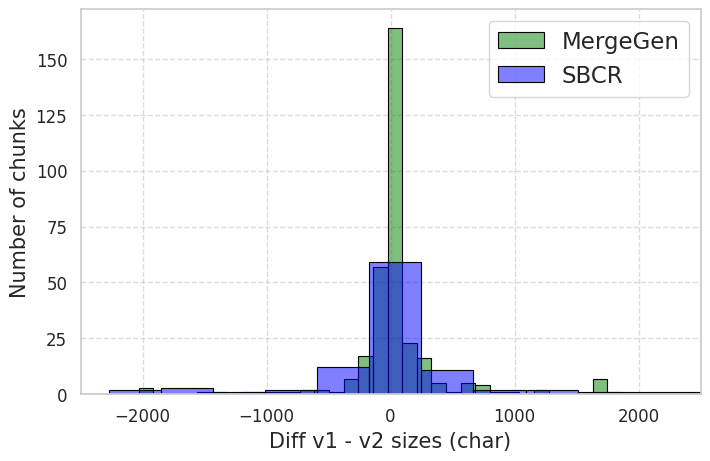

In [24]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char'], bins=50, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char'],bins=50, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-2500,2500)
plt.legend()
plt.show()

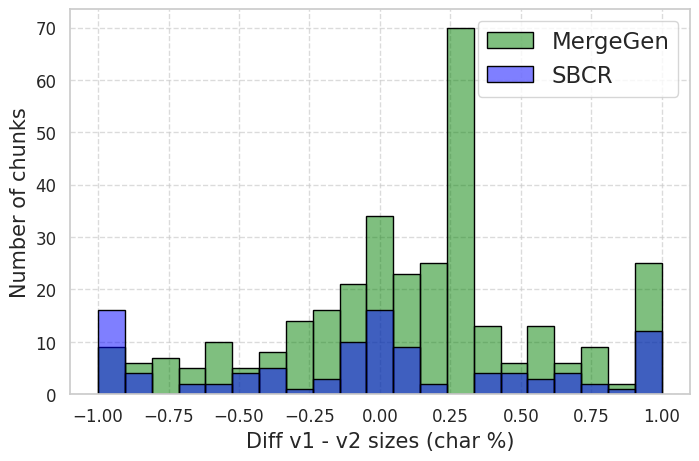

In [25]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char_rel'], bins=21, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char_rel'], bins=21, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

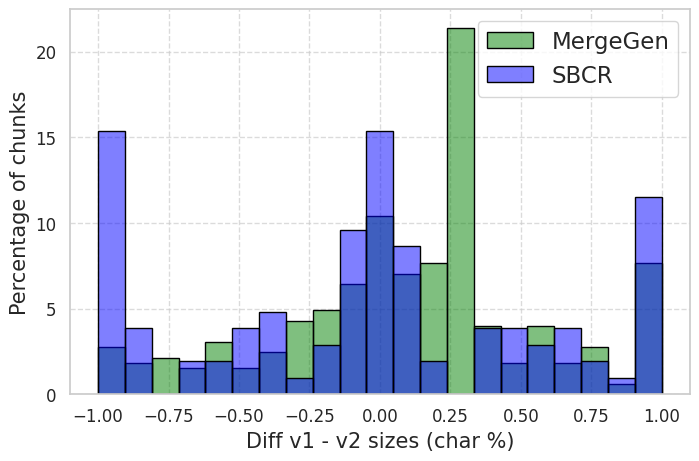

In [26]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char_rel'], bins=21, stat='percent',color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char_rel'], bins=21, stat='percent', color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()